# 06 Noise

The two-stage matrix imaging test from 05, with noise added to R. Noise shrinks with recording time
(1/sqrt(days)) and is set against a fixed reference signal, so designs with weaker echoes or shorter recording
suffer more. The true noise level at Rotokawa is unknown, so a range is scanned.

In [2]:
%run mi_common.py

In [3]:
NSR_LIST = [0.25, 0.5, 1.0, 2.0]       # noise / signal for 30 days of recording at the reference geometry. scanned
DAYS_REF = 30                          # recording time the NSR values refer to (days)
REF = "1d"                             # focusing model for decisions and images (the realistic one)
SHAPES_RUN = ["dome", "lens"]          # fewer shapes keeps the run time down; add more once it works

# recording time per stage
P1_DAYS = p2["p1_days"]
PATCH_DAYS = p2["patch_days"]
STATIC_DAYS = P1_DAYS + len(p2["order"]) * PATCH_DAYS    # static designs get the same total time as phased

RUN = [n for n, m_ in S["scenarios"].items() if m_["shape"] in SHAPES_RUN]
print(len(RUN), "scenarios x", len(NSR_LIST), "noise levels")

30 scenarios x 4 noise levels


In [4]:
def add_noise(R, days, level):
    """R plus correlation noise with std = level * sqrt(DAYS_REF / days)."""
    E = (rng.normal(size=R.shape) + 1j * rng.normal(size=R.shape)) / np.sqrt(2)
    E = (E + E.transpose(0, 2, 1)) / np.sqrt(2)                 # keep R symmetric
    return R + level * np.sqrt(DAYS_REF / days) * E

In [5]:
ref_name = next(n for n, m_ in S["scenarios"].items() if m_["shape"] == "dome" and m_["centre"] == [0.0, 0.0])
top = sc[f"top_{ref_name}"]
near = (np.hypot(MX, MY) <= SCAT_R) & ~np.isnan(top)
scat = np.column_stack([MX[near], MY[near], top[near]])
R_ref = reflection_matrix(designs["grid"][0]["stations"], scat, r0 * np.ones(len(scat)))
SIGNAL = np.sqrt(np.mean(np.abs(R_ref) ** 2))                    # rms echo strength
print(f"reference: {ref_name}, rms signal {SIGNAL:.2e}")

reference: pos00_dome, rms signal 1.34e-04


In [6]:
rows = []
for nsr in NSR_LIST:
    level = nsr * SIGNAL
    for name in RUN:
        meta = S["scenarios"][name]
        c0, top = meta["centre"], sc[f"top_{name}"]
        near = (np.hypot(MX - c0[0], MY - c0[1]) <= SCAT_R) & ~np.isnan(top)
        scat = np.column_stack([MX[near], MY[near], top[near]])
        sigma = r0 * (1 + ROUGH * rng.normal(size=len(scat)))
        cx, cy, zc, pts = columns(c0)
        true_top = top_at(top, cx, cy)

        # phased: noisy phase 1 picks the centre, noisy phase 2 images there
        st1 = designs["phased"][0]["stations"]
        R1 = add_noise(reflection_matrix(st1, scat, sigma), P1_DAYS, level)
        m1 = image(R1, st1, p1_pts, REF).reshape(V1x.shape).max(axis=2)
        k = np.unravel_index(m1.argmax(), m1.shape)
        chosen = (P1_H[k[0]], P1_H[k[1]])
        err = np.hypot(chosen[0] - c0[0], chosen[1] - c0[1])

        patches = phase2_patches(chosen)
        I = sum(image(add_noise(reflection_matrix(p, scat, sigma), PATCH_DAYS, level), p, pts, REF)
                for p in patches)
        rows.append((nsr, name, meta["shape"], "phased", err, coverage(I, cx, cy, zc, true_top, c0)))

        # static designs over the same total time
        for dname in STATIC:
            st_ = designs[dname][0]["stations"]
            R = add_noise(reflection_matrix(st_, scat, sigma), STATIC_DAYS, level)
            rows.append((nsr, name, meta["shape"], dname, np.nan,
                         coverage(image(R, st_, pts, REF), cx, cy, zc, true_top, c0)))
    print(f"NSR {nsr} done")

noisy = pd.DataFrame(rows, columns=["nsr", "scenario", "shape", "design", "p1_error", "coverage"])

NSR 0.25 done
NSR 0.5 done
NSR 1.0 done
NSR 2.0 done


In [7]:
# --- Coverage vs noise: average and worst case over scenarios ---
print(noisy.groupby(["design", "nsr"]).coverage.agg(mean="mean", worst="min").round(2).unstack("nsr"))

# --- Phase 1 location error vs noise ---
print("\nPhase 1 location error (km)")
print(noisy[noisy.design == "phased"].groupby("nsr").p1_error.agg(median="median", worst="max").round(1))

           mean                   worst                  
nsr        0.25  0.50  1.00  2.00  0.25  0.50  1.00  2.00
design                                                   
grid       0.12  0.12  0.13  0.12  0.04  0.02  0.04  0.04
phased     0.43  0.43  0.43  0.44  0.15  0.15  0.14  0.14
spiral     0.23  0.23  0.23  0.23  0.09  0.09  0.09  0.09
wide grid  0.17  0.17  0.17  0.18  0.06  0.06  0.05  0.05

Phase 1 location error (km)
      median  worst
nsr                
0.25     1.0    2.5
0.50     1.0    2.1
1.00     1.0    2.5
2.00     1.0    2.5


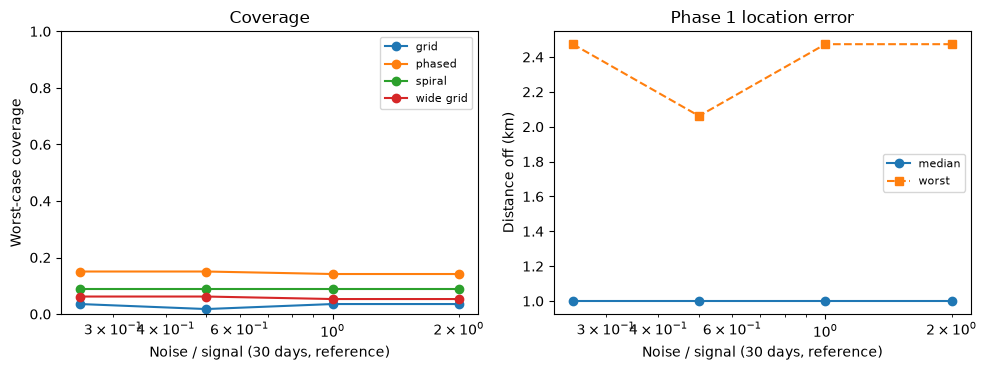

In [8]:
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
    for dname, grp in noisy.groupby("design"):
        w = grp.groupby("nsr").coverage.min()
        ax1.plot(w.index, w.values, "o-", label=dname)
    ax1.set(xscale="log", xlabel="Noise / signal (30 days, reference)", ylabel="Worst-case coverage",
            ylim=(0, 1), title="Coverage")
    ax1.legend(fontsize=8)

    p = noisy[noisy.design == "phased"].groupby("nsr").p1_error
    ax2.plot(p.median().index, p.median().values, "o-", label="median")
    ax2.plot(p.max().index, p.max().values, "s--", label="worst")
    ax2.set(xscale="log", xlabel="Noise / signal (30 days, reference)", ylabel="Distance off (km)",
            title="Phase 1 location error")
    ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()